# FXS / 03 — Account growth trading every frozen structure (sizing only, no gates)

Question (Iván, 2026-11-09): how does an account grow trading **all** the intraday structures found in FXS 01, with position size increasing as equity grows?

**What is simulated.** Every frozen candidate from the 15 pair folders, traded every day exactly as frozen (time, direction), at quoted bid/ask, minus 0.70 bp commission. Each day every structure trades `floor(equity × w / 1,000) × 1,000` units, so size compounds with equity.

| Window | Role |
|---|---|
| **2021–2025** | **out of sample**: the structures were chosen without these years. This is the result to read. |
| 2016–2020 | in sample: the same years that selected the structures. Shown for contrast only; it is biased upward by construction. |

**Sizing schemes**
- **A. Fixed leverage per structure** L = 1, 2, 5, 10 (notional = L × equity on each structure).
- **B. Half-Kelly**, estimated on 2016–2020 only and applied unchanged to 2021–2025 (the honest ex-ante version), uncapped and capped at 30× total.
- **C. Hindsight**, only the structures that were positive after spread in 2021–2025. **Uses confirmation results to choose: not a valid test**, shown as an upper bound.

FXS 02's verdicts (0 of 10 confirmed) are unchanged by this notebook. `FXS_SYNTHETIC=1` runs offline on two synthetic structures.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 10_000.0              # starting equity, USD
LEVERAGES = [1, 2, 5, 10]  # scheme A: notional per structure as a multiple of equity
EU_CAP = 30.0              # scheme B cap on total notional (EU retail FX limit)

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03_synthetic" if SYNTHETIC else "03"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for p, drift in (("EURUSD", 4.0), ("USDJPY", 0.0)):
        for a, b in [(dt.date(2015, 12, 28), dt.date(2020, 12, 31)), (dt.date(2020, 12, 28), dt.date(2025, 12, 31))]:
            F.write_synthetic_candles(base, p, a, b, seed=a.year + len(p), drift_bps=drift, price=110.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": "EURUSD-01", "pair": "EURUSD", "clock": "NY", "start": 900, "end": 960, "direction": 1,
                          "start_time": "NY 08:00", "end_time": "NY 09:00"},
                         {"id": "USDJPY-01", "pair": "USDJPY", "clock": "UTC", "start": 60, "end": 120, "direction": 1,
                          "start_time": "UTC 01:00", "end_time": "UTC 02:00"}])
else:
    cand = F.load_frozen_candidates(BRANCH)

## 1. The structures

In [3]:
display(cand[["id", "clock", "start_time", "end_time", "direction"] + [c for c in ("mean_bps", "t") if c in cand]].round(3))
conc = F.max_concurrent(cand)
print(f"{len(cand)} structures; at most {conc} open at the same minute")

,id,clock,start_time,end_time,direction,mean_bps,t
0,EURUSD-01,UTC,UTC 01:15,UTC 03:15,1,1.301,4.579
1,EURUSD-02,NY,NY 04:00,NY 08:00,-1,-2.486,-4.085
2,USDJPY-01,UTC,UTC 00:55,UTC 01:55,-1,-1.868,-4.905
3,USDJPY-02,UTC,UTC 00:25,UTC 00:55,1,1.067,4.067
4,USDCHF-01,NY,NY 04:00,NY 08:00,1,1.982,3.375
5,AUDUSD-01,NY,NY 21:50,NY 01:50,1,2.046,3.518
6,EURJPY-01,NY,NY 10:45,NY 11:00,-1,-1.194,-4.147
7,EURJPY-02,NY,NY 12:35,NY 16:35,1,1.837,4.128
8,AUDJPY-01,NY,NY 13:40,NY 15:40,1,1.668,3.860
9,CADJPY-01,NY,NY 13:40,NY 15:40,1,1.879,4.113


10 structures; at most 3 open at the same minute


## 2. Daily net returns per structure

Net = after the quoted spread and 0.70 bp commission, in bps of notional, one trade per structure per day.

,in-sample mean bps,in-sample total bps,OUT-OF-SAMPLE mean bps,OUT-OF-SAMPLE total bps,out-of-sample days
EURUSD-01,0.29,370.35,-0.55,-717.72,1298
EURUSD-02,1.53,1979.26,0.96,1245.70,1298
USDJPY-01,0.85,1100.97,0.23,302.30,1298
USDJPY-02,0.04,50.87,0.17,217.42,1298
USDCHF-01,0.28,362.43,-0.53,-687.12,1298
AUDUSD-01,0.01,12.11,-1.80,-2334.99,1297
EURJPY-01,0.08,97.32,-1.56,-2023.58,1298
EURJPY-02,0.52,675.84,0.11,139.98,1298
AUDJPY-01,-0.02,-19.79,-1.18,-1535.17,1298
CADJPY-01,-0.07,-97.21,-1.91,-2485.01,1298


equal-weight portfolio, mean net per day: in-sample 0.349 bp, out-of-sample -0.607 bp


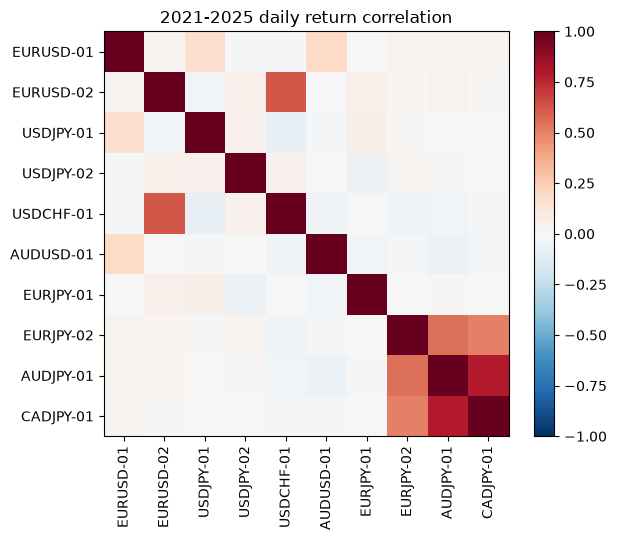

In [4]:
R_in = F.structure_returns(cand, *F.DISCOVERY, "discovery", cfg)
R_out = F.structure_returns(cand, *F.CONFIRMATION, "confirmation", cfg)
tab = pd.DataFrame({"in-sample mean bps": R_in.mean(), "in-sample total bps": R_in.sum(),
                    "OUT-OF-SAMPLE mean bps": R_out.mean(), "OUT-OF-SAMPLE total bps": R_out.sum(),
                    "out-of-sample days": (R_out != 0).sum()})
display(tab.round(2)); tab.to_csv(OUT / "03_structure_returns.csv")
print(f"equal-weight portfolio, mean net per day: in-sample {R_in.mean(axis=1).mean():.3f} bp, out-of-sample {R_out.mean(axis=1).mean():.3f} bp")
if R_out.shape[1] > 1:
    corr = R_out.corr()
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
    ax.set_title("2021-2025 daily return correlation"); fig.colorbar(im, ax=ax, fraction=0.04)
    plt.tight_layout(); plt.savefig(OUT / "03_correlation.png", dpi=110); plt.show()

## 3. Scheme A: fixed leverage per structure, compounding

Each structure gets L × equity of notional every day. With all structures open at once the total is up to (number open) × L.

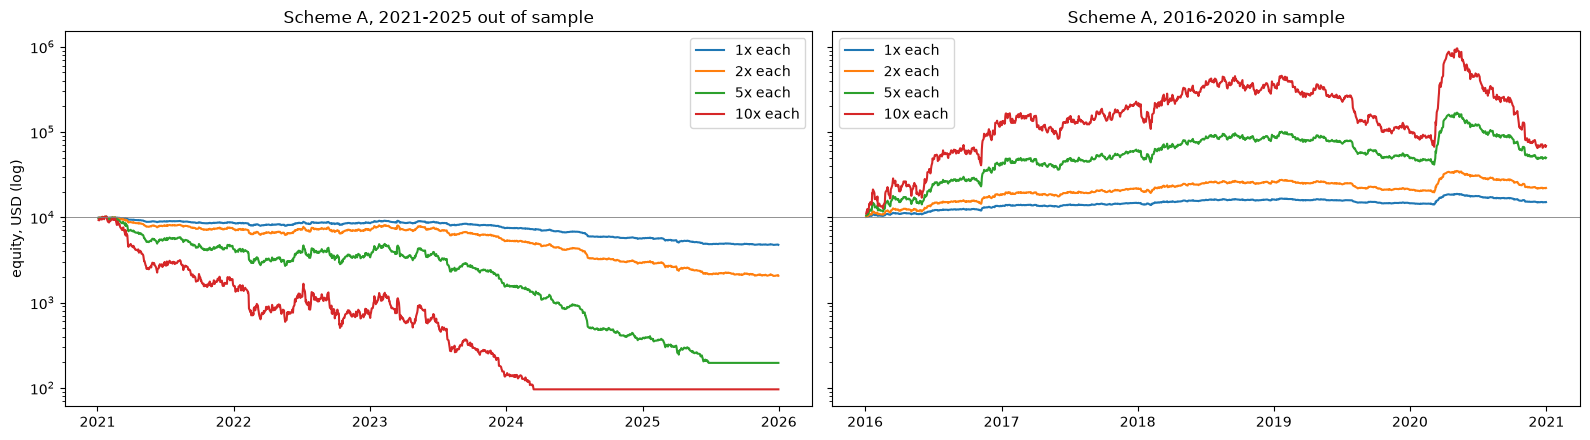

In [5]:
rows, curves = [], {}
for window, R in (("2021-2025 out of sample", R_out), ("2016-2020 in sample", R_in)):
    for L in LEVERAGES:
        acc = F.simulate_account(R, pd.Series(float(L), index=R.columns), E0)
        curves[(window, L)] = acc
        rows.append({"window": window, "scheme": f"A: {L}x each", "max_total_notional_x": L * conc, **F.account_stats(acc, E0)})
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, window in zip(axes, ("2021-2025 out of sample", "2016-2020 in sample")):
    for L in LEVERAGES:
        ax.plot(curves[(window, L)]["equity"].clip(lower=1), label=f"{L}x each")
    ax.axhline(E0, color="grey", lw=0.6); ax.set_yscale("log"); ax.set_title(f"Scheme A, {window}"); ax.legend()
axes[0].set_ylabel("equity, USD (log)")
plt.tight_layout(); plt.savefig(OUT / "03_scheme_A.png", dpi=110); plt.show()

## 4. Scheme B: half-Kelly estimated on 2016–2020, applied to 2021–2025

The sizes are decided before seeing 2021–2025, as they would have been in real trading. Structures with a negative Kelly weight get zero.

,half-Kelly notional x equity,capped at 30x total
EURUSD-01,8.48,4.00
EURUSD-02,17.18,8.11
USDJPY-01,22.48,10.61
USDJPY-02,0.00,0.00
USDCHF-01,0.00,0.00
AUDUSD-01,1.03,0.49
EURJPY-01,4.38,2.07
EURJPY-02,9.99,4.72
AUDJPY-01,0.00,0.00
CADJPY-01,0.00,0.00


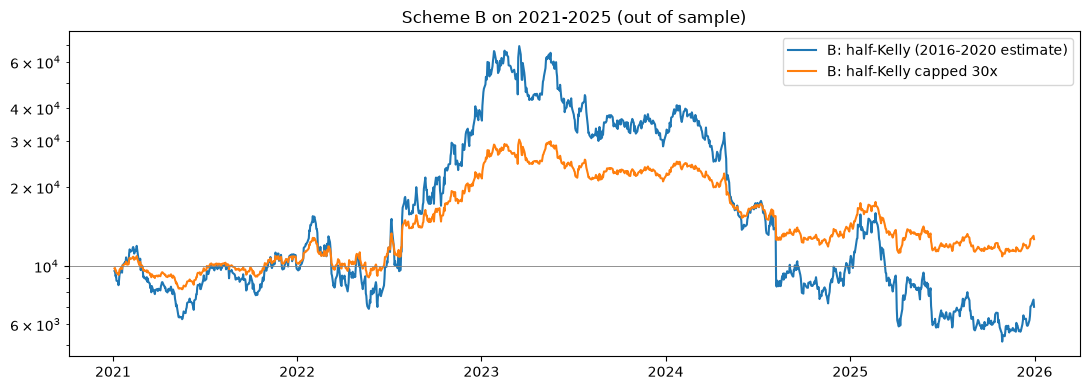

In [6]:
wB = F.kelly_weights(R_in, 0.5)
wBc = F.kelly_weights(R_in, 0.5, cap_total=EU_CAP)
display(pd.DataFrame({"half-Kelly notional x equity": wB, f"capped at {EU_CAP:.0f}x total": wBc}).round(2))
for name, w in (("B: half-Kelly (2016-2020 estimate)", wB), (f"B: half-Kelly capped {EU_CAP:.0f}x", wBc)):
    for window, R in (("2021-2025 out of sample", R_out), ("2016-2020 in sample", R_in)):
        acc = F.simulate_account(R, w, E0)
        curves[(window, name)] = acc
        rows.append({"window": window, "scheme": name, "max_total_notional_x": float(w.sum()), **F.account_stats(acc, E0)})
fig, ax = plt.subplots(figsize=(11, 4))
for name in ("B: half-Kelly (2016-2020 estimate)", f"B: half-Kelly capped {EU_CAP:.0f}x"):
    ax.plot(curves[("2021-2025 out of sample", name)]["equity"].clip(lower=1), label=name)
ax.axhline(E0, color="grey", lw=0.6); ax.set_yscale("log"); ax.legend(); ax.set_title("Scheme B on 2021-2025 (out of sample)")
plt.tight_layout(); plt.savefig(OUT / "03_scheme_B.png", dpi=110); plt.show()

## 5. Scheme C: hindsight (NOT a valid test)

Only the structures whose 2021–2025 mean after spread was positive and significant (K1). Choosing them uses the results being measured, so this is an upper bound, not an expectation.

In [7]:
conf = []
for p in sorted(set(cand["pair"])):
    f = BRANCH / p / "02" / "02_confirmation.csv"
    if f.exists():
        conf.append(pd.read_csv(f))
hind = (pd.concat(conf).query("K1 == True")["id"].tolist() if conf else [])
if SYNTHETIC:
    hind = [c for c in R_out.columns if R_out[c].mean() > 0]
print("hindsight set:", hind)
if hind:
    for L in LEVERAGES:
        acc = F.simulate_account(R_out[hind], pd.Series(float(L), index=hind), E0)
        curves[("2021-2025 out of sample", f"C{L}")] = acc
        rows.append({"window": "2021-2025 out of sample", "scheme": f"C (hindsight): {L}x each", "max_total_notional_x": L * len(hind),
                     **F.account_stats(acc, E0)})

hindsight set: ['EURUSD-02', 'USDJPY-01', 'USDJPY-02']


## 6. Results

In [8]:
res = pd.DataFrame(rows)
show = res.copy()
for c in ("cagr", "ann_vol", "max_drawdown", "worst_year", "best_year"):
    show[c] = (100 * show[c]).round(1).astype(str) + "%"
show["final_equity"] = show["final_equity"].round(0)
display(show.sort_values(["window", "scheme"]).reset_index(drop=True))
res.to_csv(OUT / "03_results.csv", index=False)

,window,scheme,max_total_notional_x,final_equity,cagr,ann_vol,sharpe,max_drawdown,worst_year,best_year,ruined
0,2016-2020 in sample,A: 10x each,30.000000,68732.0,47.1%,101.8%,0.863138,-93.2%,-72.6%,1101.6%,False
1,2016-2020 in sample,A: 1x each,3.000000,15042.0,8.5%,9.9%,0.854283,-20.5%,-9.8%,35.1%,False
2,2016-2020 in sample,A: 2x each,6.000000,22013.0,17.1%,20.1%,0.862106,-37.8%,-19.6%,83.0%,False
3,2016-2020 in sample,A: 5x each,15.000000,49770.0,37.9%,50.8%,0.863780,-71.4%,-44.3%,312.9%,False
4,2016-2020 in sample,B: half-Kelly (2016-2020 estimate),63.539598,1897527.0,186.1%,81.9%,1.637743,-75.7%,9.9%,467.8%,False
5,2016-2020 in sample,B: half-Kelly capped 30x,30.000000,177716.0,78.0%,38.6%,1.637341,-46.5%,8.2%,155.9%,False
6,2021-2025 out of sample,A: 10x each,30.000000,96.0,-60.6%,77.2%,-0.776278,-99.1%,-84.1%,0.0%,False
7,2021-2025 out of sample,A: 1x each,3.000000,4755.0,-13.8%,9.3%,-1.500375,-52.7%,-24.1%,0.6%,False
8,2021-2025 out of sample,A: 2x each,6.000000,2064.0,-27.1%,19.1%,-1.510396,-79.6%,-44.1%,-1.3%,False
9,2021-2025 out of sample,A: 5x each,15.000000,196.0,-54.5%,44.9%,-1.473651,-98.1%,-75.4%,-14.2%,False


## 7. Where the out-of-sample P&L came from

Scheme A at 5× each, 2021–2025: dollar P&L per structure (sizes compound with the whole account).

,USD P&L 2021-2025
CADJPY-01,-3718.0
AUDUSD-01,-2839.0
AUDJPY-01,-2543.0
EURJPY-01,-2232.0
EURUSD-01,-778.0
USDCHF-01,-620.0
EURJPY-02,-187.0
USDJPY-01,-5.0
USDJPY-02,371.0
EURUSD-02,2747.0


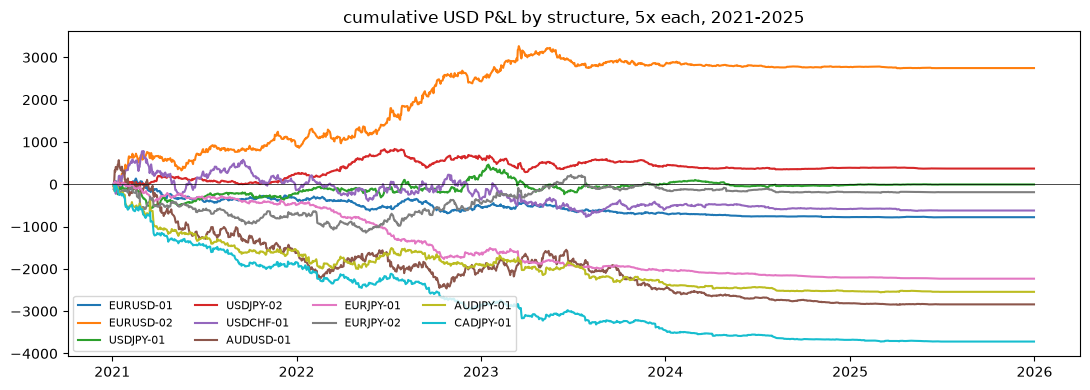

In [9]:
L = 5
acc = curves[("2021-2025 out of sample", L)]
eq_prev = acc["equity"].shift(1).fillna(E0)
units = np.floor(eq_prev.to_numpy()[:, None] * L / 1000) * 1000
pnl = pd.DataFrame(units * R_out.to_numpy() / 1e4, index=R_out.index, columns=R_out.columns)
contrib = pnl.sum().sort_values()
display(contrib.round(0).to_frame("USD P&L 2021-2025"))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pnl.cumsum()); ax.axhline(0, color="black", lw=0.5); ax.legend(pnl.columns, ncol=4, fontsize=8)
ax.set_title(f"cumulative USD P&L by structure, {L}x each, 2021-2025"); plt.tight_layout(); plt.savefig(OUT / "03_contribution.png", dpi=110); plt.show()

In [10]:
summary = {"study": "FXS03", "fxs_version": F.FXS_VERSION, "synthetic": SYNTHETIC, "equity0": E0,
           "structures": cand["id"].tolist(), "max_concurrent": conc,
           "equal_weight_mean_net_bps": {"in_sample": float(R_in.mean(axis=1).mean()), "out_of_sample": float(R_out.mean(axis=1).mean())},
           "kelly_weights_half": wB.round(3).to_dict(), "hindsight_set": hind, "results": res.to_dict(orient="records"),
           "note": "Sizing only. FXS 02 verdicts unchanged; scheme C uses confirmation results to choose and is not a test."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("structures", "max_concurrent", "equal_weight_mean_net_bps")}, indent=2))

{
  "structures": [
    "EURUSD-01",
    "EURUSD-02",
    "USDJPY-01",
    "USDJPY-02",
    "USDCHF-01",
    "AUDUSD-01",
    "EURJPY-01",
    "EURJPY-02",
    "AUDJPY-01",
    "CADJPY-01"
  ],
  "max_concurrent": 3,
  "equal_weight_mean_net_bps": {
    "in_sample": 0.34943241833164357,
    "out_of_sample": -0.6069490612561516
  }
}
